# Baselines

Un score de 71 % ne dit rien tant qu'on ne sait pas ce que donnent des approches simples. Ce notebook compare les modèles à des références de difficulté croissante :

| Référence | Principe |
| --- | --- |
| Classe majoritaire | probabilité constante, égale au taux de victoire T du train |
| Règle « joueurs vivants » | l'équipe qui a le plus de joueurs vivants gagne (égalité : 50 %) |
| Règle « joueurs vivants + bombe » | idem ; en cas d'égalité, bombe posée → T, sinon → CT (sans bombe, le temps joue pour les CT) |
| Table « écart de joueurs » | probabilité = taux de victoire T observé dans le train pour le même écart de joueurs |
| Table « écart de joueurs × bombe » | idem, en distinguant bombe posée / non posée |
| Régression logistique (4 variables) | écart de joueurs, bombe, temps restant avant et après la bombe |

Même protocole que pour les modèles : validation croisée groupée par match (`GroupKFold`, 5 plis) sur le train.

## 0. Imports et données

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict

from src.config import ROOT_DIR, SEED, TARGET
from src.rounds import load_processed
from src.features import build_pipeline
from src.baselines import AliveRule, FrequencyTable, simple_logistic_regression
from src.evaluation import grouped_cv, summarize_cv
from src.viz import COLOR_CT, COLOR_TEXT, COLOR_TEXT_MUTED, save_fig, set_style

set_style()
df = load_processed()
train = df[df["split"] == "train"].reset_index(drop=True)
print(f"Train : {len(train):,} lignes, {train['match_id'].nunique()} matchs")

Train : 97,431 lignes, 560 matchs


## 1. Validation croisée

In [2]:
candidates = {
    "Classe majoritaire": DummyClassifier(strategy="prior"),
    "Règle : joueurs vivants": AliveRule(),
    "Règle : joueurs vivants + bombe": AliveRule(bomb_tiebreak=True),
    "Table : écart de joueurs": FrequencyTable(),
    "Table : écart de joueurs × bombe": FrequencyTable(use_bomb=True),
    "Régression logistique (4 variables)": simple_logistic_regression(),
    "Régression logistique (49 variables)": build_pipeline(LogisticRegression(max_iter=2000), scale=True),
    "Gradient Boosting (49 variables)": build_pipeline(HistGradientBoostingClassifier(random_state=SEED)),
}
kind = {name: ("modèle" if "49 variables" in name else "référence") for name in candidates}

cv = {name: grouped_cv(est, train) for name, est in candidates.items()}
results = summarize_cv(cv)
results.insert(1, "type", results["configuration"].map(kind))

reports = ROOT_DIR / "reports"
reports.mkdir(exist_ok=True)
results.to_csv(reports / "cv_baselines.csv", index=False)

results[["configuration", "type", "accuracy", "accuracy_std", "roc_auc", "log_loss", "brier"]].style.format(
    {"accuracy": "{:.2%}", "accuracy_std": "± {:.2%}", "roc_auc": "{:.4f}",
     "log_loss": "{:.4f}", "brier": "{:.4f}"}).hide(axis="index")

configuration,type,accuracy,accuracy_std,roc_auc,log_loss,brier
Classe majoritaire,référence,51.14%,± 1.14%,0.5000,0.6930,0.2499
Règle : joueurs vivants,référence,62.01%,± 0.97%,0.6980,1.1301,0.2148
Règle : joueurs vivants + bombe,référence,62.80%,± 0.48%,0.6352,5.1394,0.3720
Table : écart de joueurs,référence,61.64%,± 0.89%,0.7032,0.5823,0.2043
Table : écart de joueurs × bombe,référence,62.78%,± 0.48%,0.7111,0.5754,0.2020
Régression logistique (4 variables),référence,62.66%,± 0.69%,0.7132,0.5769,0.2024
Régression logistique (49 variables),modèle,70.25%,± 0.51%,0.7960,0.5303,0.1821
Gradient Boosting (49 variables),modèle,70.92%,± 0.64%,0.8051,0.5159,0.1771


Les règles fixes donnent des probabilités de 0 ou 1. Quand elles se trompent, la log loss explose : elle pénalise lourdement une prédiction fausse faite avec certitude. Leur log loss n'est donc pas comparable à celle des autres approches ; seules l'accuracy et le Brier ont un sens pour elles.

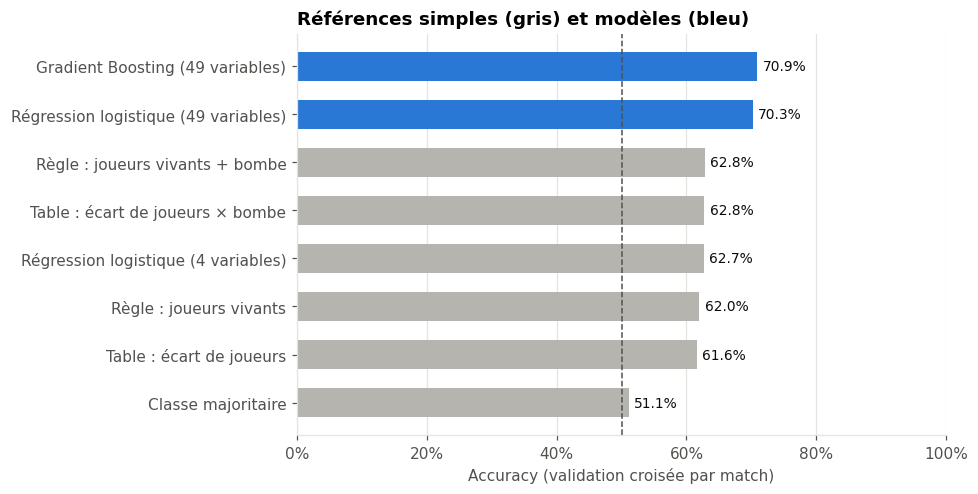

In [3]:
plot = results.sort_values("accuracy")
colors = [COLOR_CT if k == "modèle" else "#b5b4ae" for k in plot["type"]]

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(plot["configuration"], plot["accuracy"], color=colors, height=0.6)
for y, v in enumerate(plot["accuracy"]):
    ax.text(v + 0.008, y, f"{v:.1%}", va="center", fontsize=9, color=COLOR_TEXT)
ax.axvline(0.5, color=COLOR_TEXT_MUTED, linestyle="--", linewidth=1)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Accuracy (validation croisée par match)")
ax.set_title("Références simples (gris) et modèles (bleu)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "11_baselines")
plt.show()

## 2. Où le modèle apporte-t-il quelque chose ?

La meilleure table de fréquences résume la situation par deux informations : l'écart de joueurs et la bombe. Le Gradient Boosting utilise en plus l'équipement, l'argent, le temps et la carte. On compare les deux selon le moment du round, avec les prédictions de validation croisée (chaque ligne est prédite par un modèle qui n'a pas vu son match).

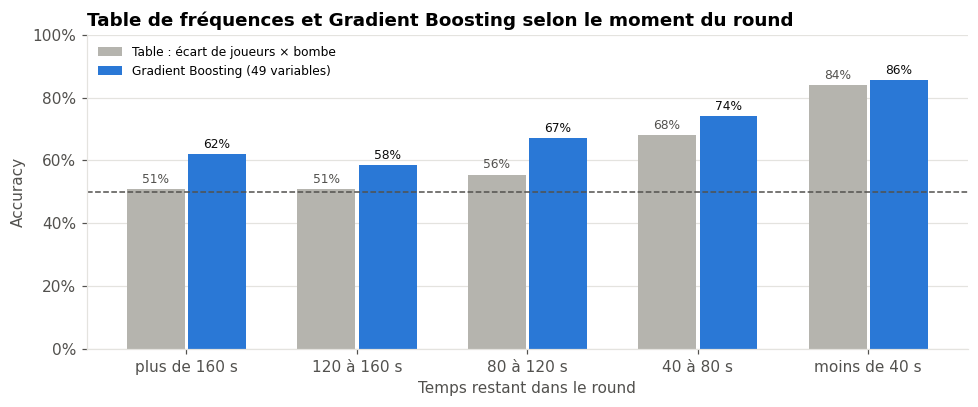

,Table : écart de joueurs × bombe,Gradient Boosting (49 variables),gain (points),part des lignes
time_left,,,,
plus de 160 s,51.0%,62.0%,+11.0,27%
120 à 160 s,50.9%,58.4%,+7.6,1%
80 à 120 s,55.5%,67.0%,+11.5,30%
40 à 80 s,68.0%,74.1%,+6.1,23%
moins de 40 s,83.9%,85.5%,+1.7,20%


In [4]:
cv_split = GroupKFold(n_splits=5)
pred = pd.DataFrame({
    "Table : écart de joueurs × bombe": cross_val_predict(
        FrequencyTable(use_bomb=True), train, train[TARGET], groups=train["match_id"],
        cv=cv_split, method="predict_proba")[:, 1],
    "Gradient Boosting (49 variables)": cross_val_predict(
        build_pipeline(HistGradientBoostingClassifier(random_state=SEED)), train, train[TARGET],
        groups=train["match_id"], cv=cv_split, method="predict_proba")[:, 1],
})
correct = pred.ge(0.5).astype(int).eq(train[TARGET], axis=0)
phase = pd.cut(train["time_left"], [-1, 40, 80, 120, 160, 176],
               labels=["moins de 40 s", "40 à 80 s", "80 à 120 s", "120 à 160 s", "plus de 160 s"])
by_phase = correct.groupby(phase, observed=True).mean().iloc[::-1]
by_phase["gain (points)"] = 100 * (by_phase.iloc[:, 1] - by_phase.iloc[:, 0])
by_phase["part des lignes"] = phase.value_counts(normalize=True).reindex(by_phase.index)

fig, ax = plt.subplots(figsize=(9, 3.8))
x = range(len(by_phase))
ax.bar([i - 0.18 for i in x], by_phase.iloc[:, 0], width=0.34, color="#b5b4ae", label=by_phase.columns[0])
ax.bar([i + 0.18 for i in x], by_phase.iloc[:, 1], width=0.34, color=COLOR_CT, label=by_phase.columns[1])
for i, (a, b) in enumerate(zip(by_phase.iloc[:, 0], by_phase.iloc[:, 1])):
    ax.text(i - 0.18, a + 0.01, f"{a:.0%}", ha="center", va="bottom", fontsize=8, color=COLOR_TEXT_MUTED)
    ax.text(i + 0.18, b + 0.01, f"{b:.0%}", ha="center", va="bottom", fontsize=8, color=COLOR_TEXT)
ax.axhline(0.5, color=COLOR_TEXT_MUTED, linestyle="--", linewidth=1)
ax.set_xticks(list(x), by_phase.index.astype(str))
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Temps restant dans le round")
ax.set_ylabel("Accuracy")
ax.set_title("Table de fréquences et Gradient Boosting selon le moment du round")
ax.legend(loc="upper left", fontsize=8)
ax.grid(axis="x", visible=False)
plt.tight_layout()
save_fig(fig, "12_gain_par_phase")
plt.show()

by_phase.style.format({by_phase.columns[0]: "{:.1%}", by_phase.columns[1]: "{:.1%}",
                       "gain (points)": "{:+.1f}", "part des lignes": "{:.0%}"})

## 3. Résumé des résultats

In [5]:
r = results.set_index("configuration")
print("=== Résumé ===")
for name, row in r.iterrows():
    print(f"{name:<38}: accuracy {row['accuracy']:.2%} | AUC {row['roc_auc']:.4f} | "
          f"log loss {row['log_loss']:.4f} | Brier {row['brier']:.4f}")
best_ref = r[r["type"] == "référence"]["accuracy"].idxmax()
print(f"Meilleure référence : {best_ref} ({r.loc[best_ref, 'accuracy']:.2%})")
print(f"Gain du Gradient Boosting : {100 * (r.loc['Gradient Boosting (49 variables)', 'accuracy'] - r.loc[best_ref, 'accuracy']):+.1f} points")
print("Gain par phase (points) :", ", ".join(f"{k} {v:+.1f}" for k, v in by_phase["gain (points)"].items()))

=== Résumé ===
Classe majoritaire                    : accuracy 51.14% | AUC 0.5000 | log loss 0.6930 | Brier 0.2499
Règle : joueurs vivants               : accuracy 62.01% | AUC 0.6980 | log loss 1.1301 | Brier 0.2148
Règle : joueurs vivants + bombe       : accuracy 62.80% | AUC 0.6352 | log loss 5.1394 | Brier 0.3720
Table : écart de joueurs              : accuracy 61.64% | AUC 0.7032 | log loss 0.5823 | Brier 0.2043
Table : écart de joueurs × bombe      : accuracy 62.78% | AUC 0.7111 | log loss 0.5754 | Brier 0.2020
Régression logistique (4 variables)   : accuracy 62.66% | AUC 0.7132 | log loss 0.5769 | Brier 0.2024
Régression logistique (49 variables)  : accuracy 70.25% | AUC 0.7960 | log loss 0.5303 | Brier 0.1821
Gradient Boosting (49 variables)      : accuracy 70.92% | AUC 0.8051 | log loss 0.5159 | Brier 0.1771
Meilleure référence : Règle : joueurs vivants + bombe (62.80%)
Gain du Gradient Boosting : +8.1 points
Gain par phase (points) : plus de 160 s +11.0, 120 à 160 s +7.6, 8

## Conclusion

**Références :** la classe majoritaire atteint 51,1 %. Les meilleures références simples plafonnent toutes autour de 62,7 % : règle « joueurs vivants + bombe » (62,80 %), table écart de joueurs × bombe (62,78 %), régression logistique à 4 variables (62,66 %). Avec seulement l'écart de joueurs et la bombe, on capte donc l'essentiel de ce qu'une approche simple peut obtenir.

**Apport du modèle :** le Gradient Boosting sur les 49 variables atteint 70,92 %, soit **+8,1 points** par rapport à la meilleure référence. Il améliore aussi nettement les probabilités : ROC-AUC 0,7111 → 0,8051 et Brier 0,2020 → 0,1771 par rapport à la meilleure table de fréquences.

**Où se situe le gain :**

| Temps restant | Table écart × bombe | Gradient Boosting | Gain |
| --- | --- | --- | --- |
| plus de 160 s | 51,0 % | 62,0 % | +11,0 points |
| 80 à 120 s | 55,5 % | 67,0 % | +11,5 points |
| 40 à 80 s | 68,0 % | 74,1 % | +6,1 points |
| moins de 40 s | 83,9 % | 85,5 % | +1,7 point |

En début de round, les deux équipes sont à 5 contre 5 : la table ne fait pas mieux que le hasard (51,0 %), alors que le modèle exploite l'équipement et l'économie pour atteindre 62,0 %. En fin de round, l'écart de joueurs et la bombe suffisent presque à décider de l'issue, et le modèle n'apporte plus que 1,7 point. La valeur du modèle est donc dans la **lecture de l'économie et de l'équipement**, là où les règles simples sont aveugles.

**Probabilités des règles fixes :** les règles donnent des probabilités de 0 ou 1. Leur log loss (jusqu'à 5,14) et leur Brier (0,3720 pour la règle avec la bombe) montrent qu'une règle peut avoir une accuracy correcte tout en étant inutilisable pour estimer un risque.